# Implementasi Image Segmentation dan Morphological Processing

## 1. Pendahuluan

Image segmentation merupakan proses untuk membagi sebuah citra menjadi beberapa bagian berdasarkan karakteristik tertentu, seperti intensitas, warna, maupun fitur lainnya. Pada tugas kali ini, metode segmentasi yang digunakan adalah Otsu Thresholding, yaitu metode yang menentukan nilai ambang (threshold) secara otomatis berdasarkan distribusi histogram citra.

Setelah proses segmentasi dilakukan, hasilnya akan diproses menggunakan morphological operations. Operasi morfologi digunakan untuk memodifikasi bentuk dan struktur objek pada citra biner.

Pada tugas ini, operasi morfologi yang diimplementasikan meliputi dilation, erosion, opening, dan closing.

## 2. Tujuan

1. Memahami dan mengimplementasikan metode Otsu Thresholding untuk melakukan segmentasi citra.
2. Memahami konsep structuring element dalam morphological processing.
3. Mengimplementasikan operasi dilation, erosion, opening, dan closing tanpa menggunakan library morfologi.
4. Membandingkan hasil segmentasi sebelum dan sesudah morphological processing.
5. Menganalisis pengaruh setiap operasi morfologi terhadap hasil segmentasi.

## 3. Import Library

Pada tahap ini, beberapa library digunakan untuk membantu proses pengolahan dan visualisasi citra.

Library NumPy digunakan untuk melakukan operasi numerik dan manipulasi array. Matplotlib digunakan untuk menampilkan citra dan hasil pengolahan.

Selain itu, scikit-image digunakan hanya untuk mengambil gambar contoh (dataset) yang akan digunakan dalam tugas. Seluruh algoritma segmentasi dan morphological processing akan diimplementasikan secara manual.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

## 4. Memuat Dataset

Dataset yang digunakan adalah gambar coins yang tersedia pada library scikit-image.

Gambar ini merupakan citra grayscale yang berisi beberapa objek koin dengan background di sekitarnya.

Penggunaan gambar grayscale memudahkan proses segmentasi karena setiap piksel hanya memiliki satu nilai intensitas, yaitu antara 0 hingga 255.

Ukuran gambar: (303, 384)
Tipe data: uint8
Nilai intensitas minimum: 1
Nilai intensitas maksimum: 252


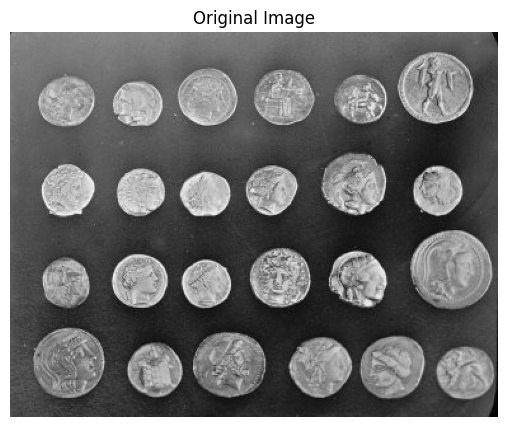

In [3]:
image = data.coins()

print("Ukuran gambar:", image.shape)
print("Tipe data:", image.dtype)
print("Nilai intensitas minimum:", image.min())
print("Nilai intensitas maksimum:", image.max())

plt.figure(figsize=(8, 5))
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis('off')
plt.show()

## 5. Image Segmentation menggunakan Otsu Thresholding

Otsu Thresholding merupakan metode segmentasi yang menentukan nilai threshold secara otomatis berdasarkan histogram citra.

Metode ini mencari nilai threshold yang dapat memisahkan piksel menjadi dua kelompok, yaitu foreground dan background, dengan memaksimalkan variansi antar-kelas (between-class variance).

Pada implementasi ini, perhitungan histogram dan pencarian nilai threshold dilakukan secara manual menggunakan NumPy, tanpa menggunakan fungsi threshold dari library pengolahan citra.

Setelah nilai threshold diperoleh:
- Piksel dengan intensitas lebih besar dari threshold akan dikategorikan sebagai foreground (putih).
- Piksel dengan intensitas lebih kecil atau sama dengan threshold akan dikategorikan sebagai background (hitam).

In [4]:
def otsu_threshold(image):
    histogram = np.bincount(image.ravel(), minlength=256)

    total_pixels = image.size

    total_intensity = np.dot(
        np.arange(256), histogram
    )

    max_variance = 0
    best_threshold = 0

    for threshold in range(256):

        weight_background = np.sum(histogram[:threshold + 1])

        weight_foreground = total_pixels - weight_background

        if weight_background == 0 or weight_foreground == 0:
            continue

        mean_background = (
            np.dot(np.arange(threshold + 1),
                   histogram[:threshold + 1])
            / weight_background
        )

        mean_foreground = (
            (total_intensity -
             np.dot(np.arange(threshold + 1),
                    histogram[:threshold + 1]))
            / weight_foreground
        )

        between_variance = (
            weight_background *
            weight_foreground *
            (mean_background - mean_foreground) ** 2
        )

        if between_variance > max_variance:
            max_variance = between_variance
            best_threshold = threshold

    return best_threshold

### 5.1 Menentukan Nilai Threshold

Setelah fungsi Otsu dibuat, selanjutnya kita mencari nilai threshold terbaik dari gambar yang digunakan.

Nilai threshold tersebut akan digunakan untuk memisahkan foreground dan background.

Nilai threshold Otsu: 107


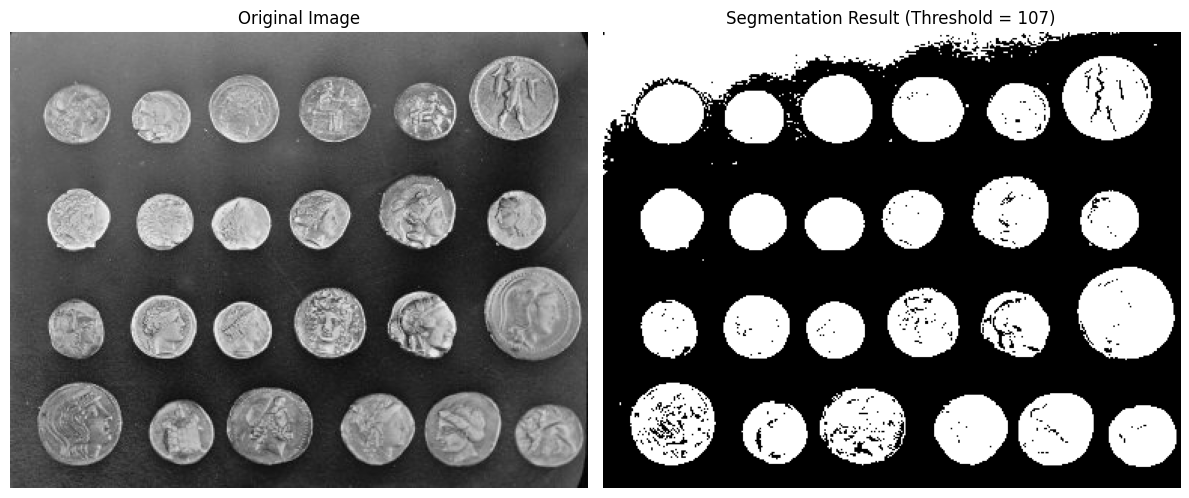

In [5]:
threshold = otsu_threshold(image)

print("Nilai threshold Otsu:", threshold)

segmented_image = image > threshold

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(segmented_image, cmap='gray')
plt.title(f"Segmentation Result (Threshold = {threshold})")
plt.axis('off')

plt.tight_layout()
plt.show()

### 5.2 Analisis Hasil Segmentasi

Berdasarkan hasil segmentasi, citra telah diubah menjadi citra biner yang terdiri dari dua kelompok piksel, yaitu foreground dan background.

Foreground ditampilkan sebagai piksel putih, sedangkan background ditampilkan sebagai piksel hitam.

Hasil segmentasi ini akan digunakan sebagai input pada tahap morphological processing.

Namun, hasil thresholding masih dapat mengandung noise, bagian objek yang terputus, atau lubang kecil pada area foreground. Oleh karena itu, diperlukan operasi morfologi untuk memperbaiki struktur objek pada citra.

## 6. Morphological Processing

Morphological processing merupakan teknik pengolahan citra yang digunakan untuk memproses bentuk dan struktur objek berdasarkan pendekatan matematika.

Operasi morfologi dasar bekerja menggunakan citra biner dan structuring element. Structuring element merupakan pola atau kernel yang digunakan untuk menentukan bagaimana setiap piksel akan diproses.

Pada implementasi ini digunakan structuring element berbentuk persegi berukuran 3x3 dengan titik origin berada di bagian tengah.

Empat operasi yang akan diimplementasikan adalah:

1. Dilation: memperbesar area foreground.
2. Erosion: memperkecil area foreground.
3. Opening: melakukan erosion kemudian dilation.
4. Closing: melakukan dilation kemudian erosion.

Seluruh operasi dilakukan secara manual menggunakan NumPy.

In [6]:
structuring_element = np.ones((3, 3), dtype=bool)

print("Structuring Element:")
print(structuring_element.astype(int))

Structuring Element:
[[1 1 1]
 [1 1 1]
 [1 1 1]]


### 6.1 Implementasi Fungsi Morphological Operation

Sebelum mengimplementasikan setiap operasi, kita membuat satu fungsi dasar yang dapat digunakan untuk melakukan dilation maupun erosion.

Cara kerjanya adalah dengan menggeser structuring element pada setiap posisi citra.

- Pada dilation, suatu piksel menjadi foreground apabila terdapat minimal satu piksel foreground yang berimpit dengan structuring element.
- Pada erosion, suatu piksel tetap menjadi foreground apabila seluruh posisi foreground pada structuring element berimpit dengan piksel foreground pada citra.

Untuk piksel di bagian tepi citra, digunakan padding dengan nilai 0 yang menunjukkan background.

In [7]:
def morphological_operation(image, kernel, operation):
    image = image.astype(bool)

    height, width = image.shape
    kernel_height, kernel_width = kernel.shape

    pad_y = kernel_height // 2
    pad_x = kernel_width // 2

    padded_image = np.pad(
        image,
        ((pad_y, pad_y), (pad_x, pad_x)),
        mode='constant',
        constant_values=0
    )

    if operation == 'dilation':
        result = np.zeros((height, width), dtype=bool)

    elif operation == 'erosion':
        result = np.ones((height, width), dtype=bool)

    else:
        raise ValueError("Operasi tidak dikenal")

    for y in range(kernel_height):
        for x in range(kernel_width):

            if kernel[y, x]:

                region = padded_image[
                    y:y + height,
                    x:x + width
                ]

                if operation == 'dilation':
                    result = result | region

                elif operation == 'erosion':
                    result = result & region

    return result

#### A. Dilation

Dilation merupakan operasi morfologi yang berfungsi untuk memperbesar area foreground (piksel putih) pada citra biner.

Proses ini dilakukan dengan mengubah piksel background menjadi foreground apabila terdapat setidaknya satu piksel foreground yang berimpit dengan structuring element.

Dilation dapat digunakan untuk memperbesar objek dan menghubungkan bagian objek yang berdekatan.

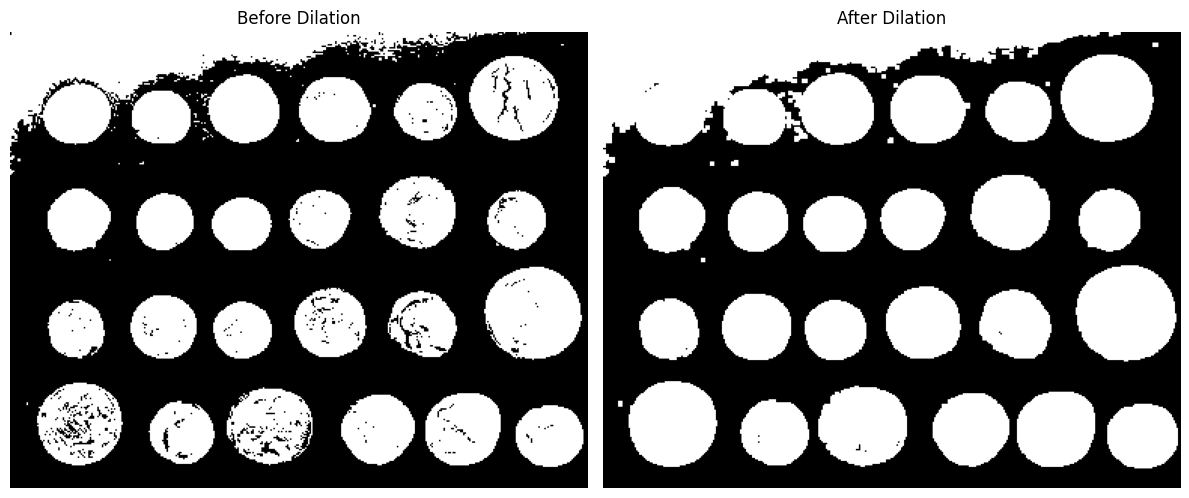

In [8]:
def dilation(image, kernel):
    return morphological_operation(
        image, kernel, 'dilation'
    )

dilated_image = dilation(
    segmented_image,
    structuring_element
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(segmented_image, cmap='gray')
plt.title("Before Dilation")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(dilated_image, cmap='gray')
plt.title("After Dilation")
plt.axis('off')

plt.tight_layout()
plt.show()

  **Analisis:**

Berdasarkan hasil yang diperoleh, dilation memperbesar area foreground dibandingkan dengan citra hasil segmentasi awal.

Hal ini terjadi karena piksel foreground dapat meluas ke area background di sekitarnya sesuai dengan bentuk structuring element yang digunakan.

Akibatnya, ukuran objek dapat bertambah dan jarak antarbagian objek dapat berkurang.

#### B. Erosion

Erosion merupakan operasi morfologi yang berfungsi untuk memperkecil area foreground pada citra biner.

Pada operasi ini, suatu piksel foreground akan dipertahankan hanya apabila seluruh posisi foreground pada structuring element berimpit dengan piksel foreground pada citra.

Apabila terdapat setidaknya satu posisi yang berimpit dengan background, piksel tersebut akan diubah menjadi background.

Erosion dapat digunakan untuk mengurangi ukuran objek dan memisahkan objek yang saling berdekatan.

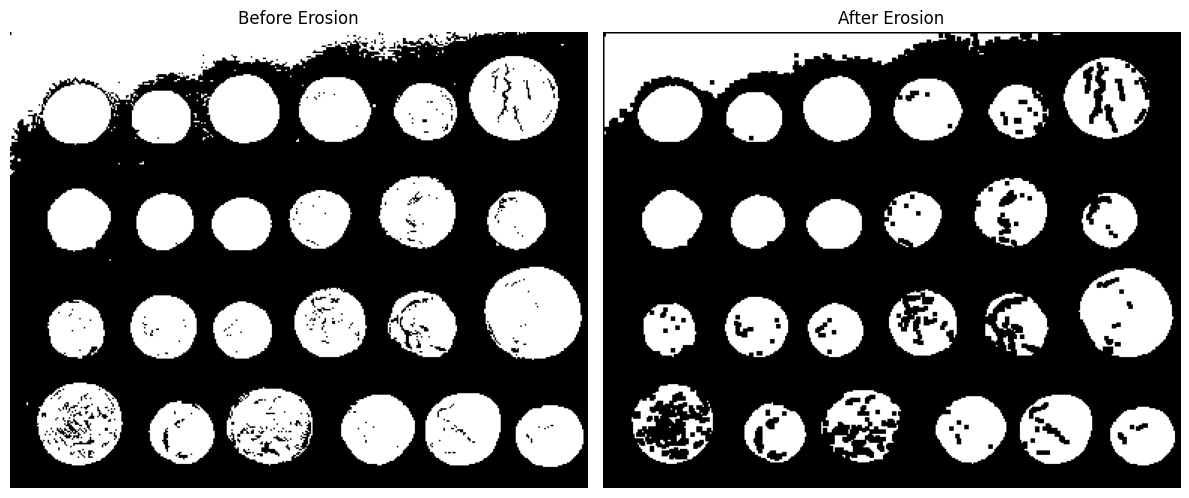

In [9]:
def erosion(image, kernel):
    return morphological_operation(
        image, kernel, 'erosion'
    )

eroded_image = erosion(
    segmented_image,
    structuring_element
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(segmented_image, cmap='gray')
plt.title("Before Erosion")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(eroded_image, cmap='gray')
plt.title("After Erosion")
plt.axis('off')

plt.tight_layout()
plt.show()

**Analisis:**

Berdasarkan hasil yang diperoleh, erosion menyebabkan area foreground menjadi lebih kecil.

Piksel yang berada pada bagian tepi objek cenderung berubah menjadi background karena tidak seluruh area structuring element berada di dalam foreground.

Dengan demikian, ukuran objek mengalami penyusutan dan bagian objek yang berukuran kecil berpotensi menghilang.

#### C. Opening

Opening merupakan operasi morfologi yang dilakukan dengan menerapkan erosion terlebih dahulu, kemudian dilanjutkan dengan dilation menggunakan structuring element yang sama.

Opening digunakan untuk menghilangkan noise berukuran kecil atau bagian foreground yang tidak sesuai dengan bentuk structuring element.

Operasi ini dapat mengurangi objek-objek kecil yang tidak diinginkan tanpa mengubah bentuk objek utama secara berlebihan.

Rumus:

Opening(A) = Dilation(Erosion(A))

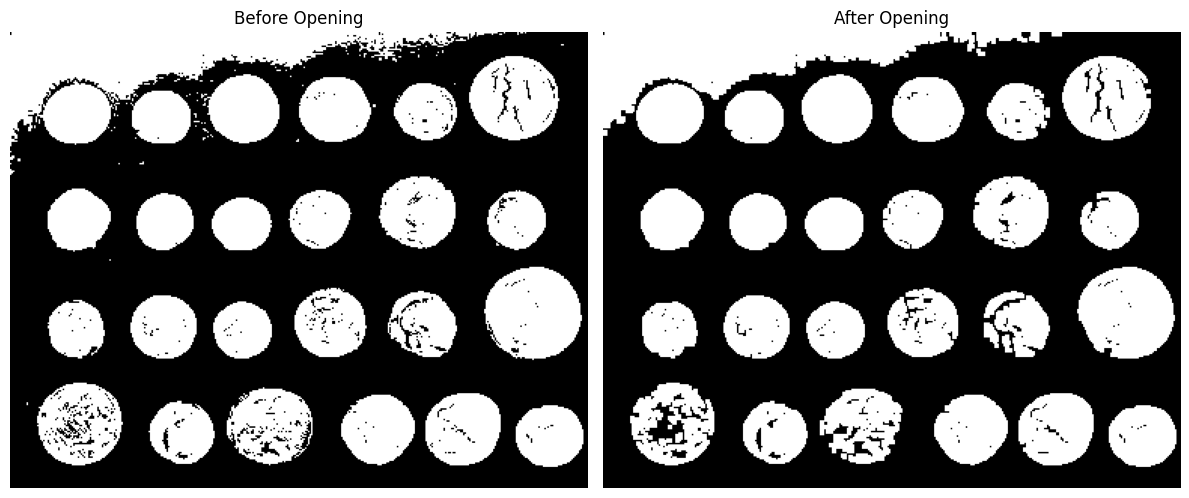

In [10]:
def opening(image, kernel):

    eroded = erosion(image, kernel)

    opened = dilation(eroded, kernel)

    return opened

opened_image = opening(
    segmented_image,
    structuring_element
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(segmented_image, cmap='gray')
plt.title("Before Opening")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(opened_image, cmap='gray')
plt.title("After Opening")
plt.axis('off')

plt.tight_layout()
plt.show()

**Analisis:**

Berdasarkan hasil yang diperoleh, opening dapat membantu menghilangkan bagian foreground berukuran kecil yang dianggap sebagai noise.

Operasi ini terlebih dahulu memperkecil area foreground melalui erosion, kemudian memperbesar kembali area yang masih bertahan melalui dilation.

Dibandingkan dengan erosion saja, opening cenderung lebih mampu mempertahankan bentuk objek utama.

#### D. Closing

Closing merupakan operasi morfologi yang dilakukan dengan menerapkan dilation terlebih dahulu, kemudian dilanjutkan dengan erosion menggunakan structuring element yang sama.

Closing digunakan untuk mengisi lubang kecil pada area foreground dan menghubungkan bagian objek yang terputus atau memiliki jarak yang berdekatan.

Rumus:

Closing(A) = Erosion(Dilation(A))

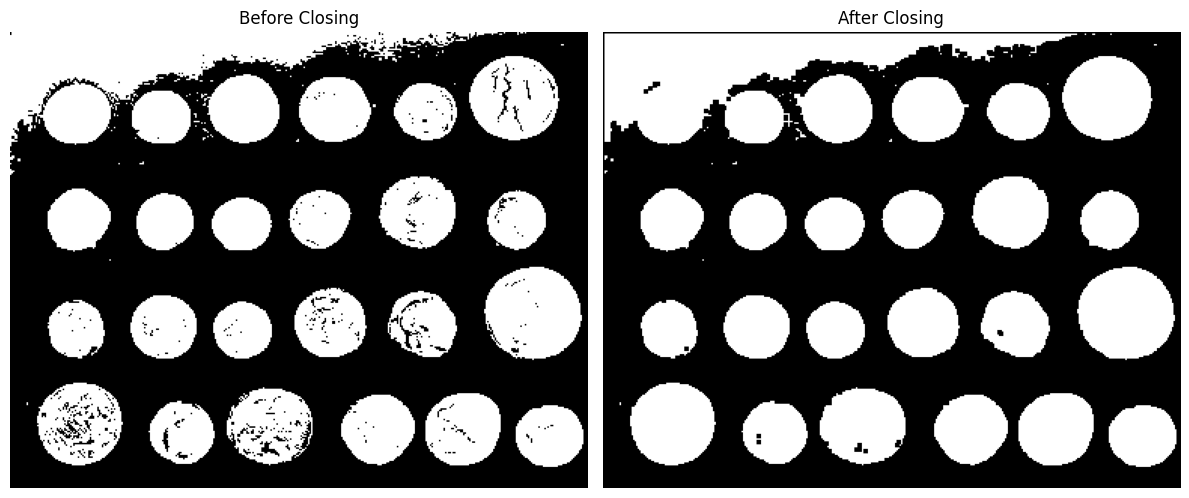

In [11]:
def closing(image, kernel):

    dilated = dilation(image, kernel)

    closed = erosion(dilated, kernel)

    return closed

closed_image = closing(
    segmented_image,
    structuring_element
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(segmented_image, cmap='gray')
plt.title("Before Closing")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(closed_image, cmap='gray')
plt.title("After Closing")
plt.axis('off')

plt.tight_layout()
plt.show()

**Analisis:**

Berdasarkan hasil yang diperoleh, closing dapat membantu mengisi lubang kecil pada area foreground dan menyambungkan bagian objek yang terputus.

Hal ini terjadi karena dilation terlebih dahulu memperluas area foreground, kemudian erosion mengembalikan ukuran objek sehingga bentuk objek utama relatif tetap terjaga.

Dengan demikian, closing dapat membantu menghasilkan area objek yang lebih utuh.

## 7. Perbandingan Hasil Segmentasi

Pada tahap ini dilakukan perbandingan antara hasil segmentasi awal dengan hasil setelah menerapkan morphological processing.

Operasi yang dibandingkan meliputi:
1. Original Segmentation: hasil segmentasi tanpa morphological processing.
2. Opening: hasil segmentasi setelah menghilangkan bagian foreground kecil.
3. Closing: hasil segmentasi setelah mengisi lubang dan celah kecil.
4. Opening + Closing: kombinasi kedua operasi untuk mengurangi noise sekaligus memperbaiki struktur objek.

Tujuan dari perbandingan ini adalah untuk mengetahui bagaimana morphological processing memengaruhi bentuk, ukuran, dan struktur objek hasil segmentasi.

In [12]:
opening_result = opening(
    segmented_image,
    structuring_element
)

combined_result = closing(
    opening_result,
    structuring_element
)

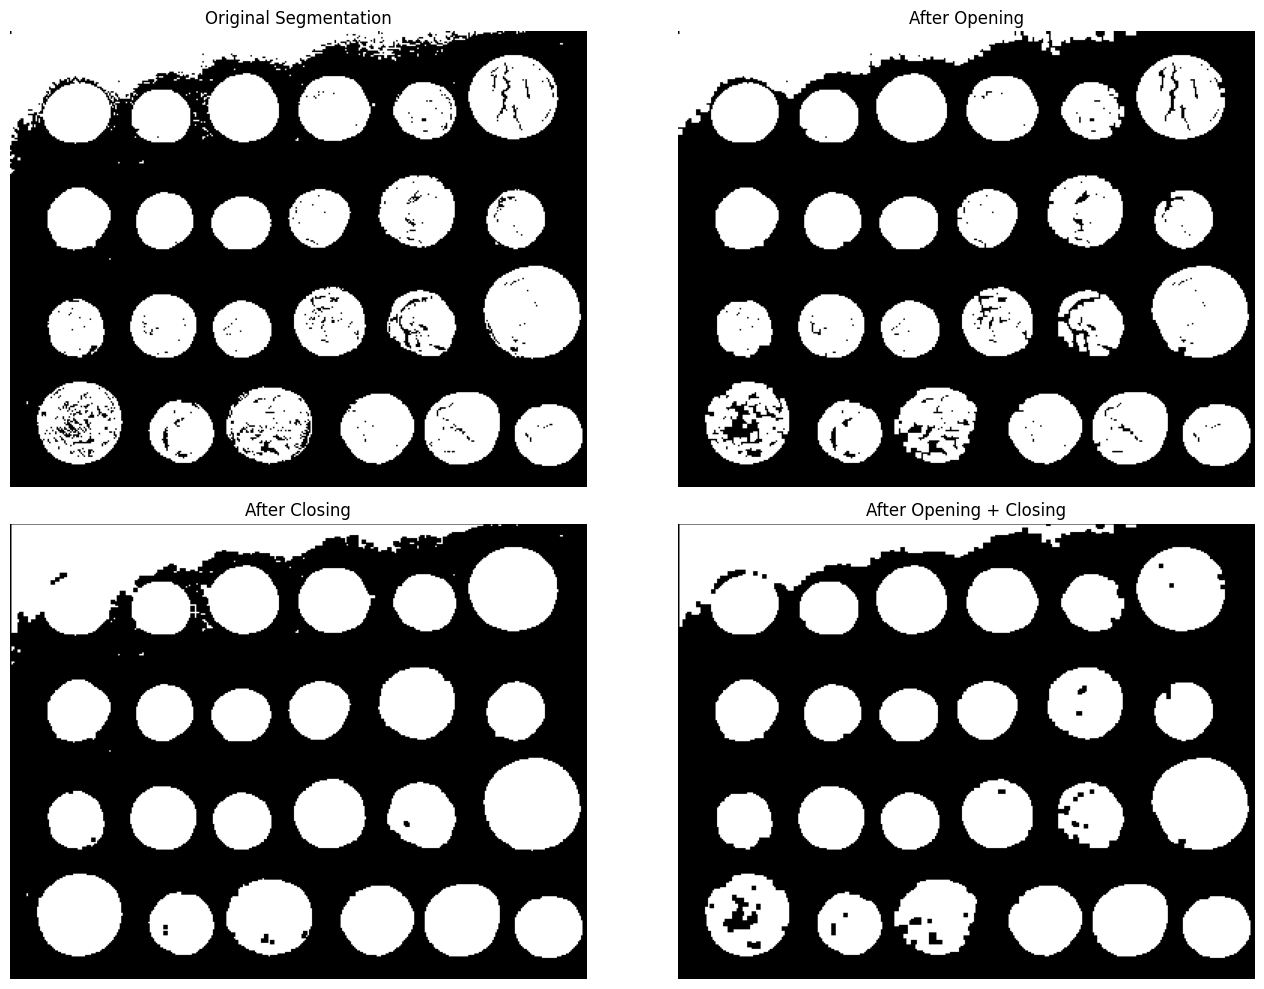

In [13]:
images = [
    segmented_image,
    opened_image,
    closed_image,
    combined_result
]

titles = [
    "Original Segmentation",
    "After Opening",
    "After Closing",
    "After Opening + Closing"
]

plt.figure(figsize=(14, 10))

for i in range(len(images)):

    plt.subplot(2, 2, i + 1)

    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

### 7.1 Analisis Perbandingan Visual

Dari hasil visualisasi, dapat diamati bahwa setiap operasi morfologi memberikan perubahan yang berbeda terhadap hasil segmentasi.

- Original Segmentation menunjukkan hasil pemisahan foreground dan background berdasarkan threshold Otsu tanpa pemrosesan morfologi tambahan.
- Opening membantu menghilangkan bagian foreground berukuran kecil yang tidak sesuai dengan structuring element.
- Closing membantu mengisi lubang kecil dan menyambungkan bagian foreground yang terputus.
- Kombinasi Opening dan Closing menggabungkan kedua efek tersebut untuk menghasilkan struktur objek yang lebih bersih.

Perubahan hasil bergantung pada karakteristik gambar dan ukuran structuring element yang digunakan.

### 7.2 Perbandingan Jumlah Foreground Pixels

Selain membandingkan hasil secara visual, dilakukan perhitungan jumlah piksel foreground pada setiap hasil pengolahan.

Perhitungan ini bertujuan untuk mengetahui perubahan luas area foreground setelah masing-masing operasi morfologi diterapkan.

In [14]:
results = {
    "Original Segmentation": segmented_image,
    "After Opening": opened_image,
    "After Closing": closed_image,
    "After Opening + Closing": combined_result
}

print("Foreground Pixel Comparison")
print("-" * 45)

for name, result in results.items():

    foreground_pixels = np.sum(result)

    print(f"{name}: {foreground_pixels}")

Foreground Pixel Comparison
---------------------------------------------
Original Segmentation: 45117
After Opening: 43566
After Closing: 46728
After Opening + Closing: 44391


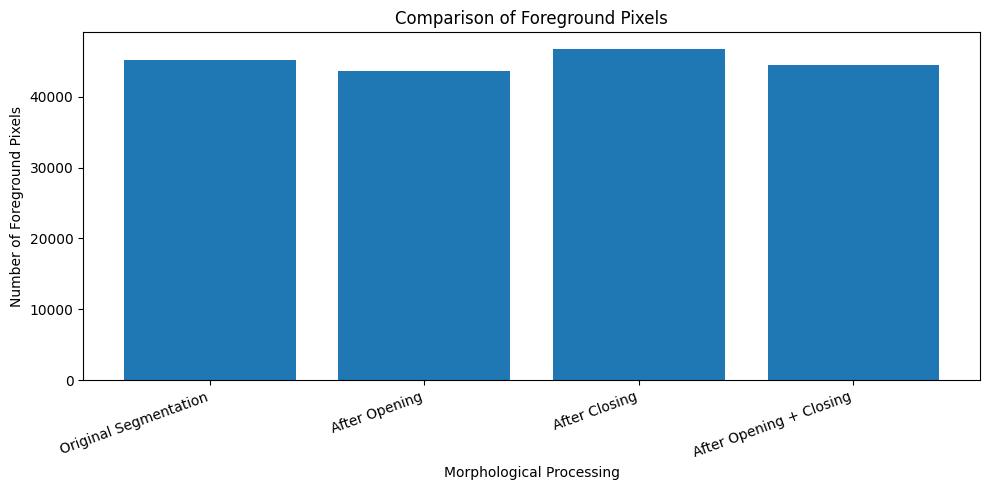

In [15]:
labels = list(results.keys())

pixel_counts = [
    np.sum(result) for result in results.values()
]

plt.figure(figsize=(10, 5))

plt.bar(labels, pixel_counts)

plt.title("Comparison of Foreground Pixels")
plt.xlabel("Morphological Processing")
plt.ylabel("Number of Foreground Pixels")

plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

### 7.3 Analisis Kuantitatif

Berdasarkan grafik perbandingan jumlah foreground pixels, dapat diamati bahwa setiap operasi morfologi menghasilkan jumlah piksel foreground yang berbeda.

Dilation secara umum meningkatkan jumlah foreground pixels karena memperluas area objek, sedangkan erosion mengurangi jumlahnya karena memperkecil area objek.

Pada opening, jumlah foreground pixels dapat berkurang karena bagian foreground berukuran kecil dihilangkan. Sementara itu, closing dapat meningkatkan jumlah foreground pixels karena mengisi lubang dan celah kecil pada objek.

Perubahan jumlah piksel tersebut menunjukkan bahwa morphological processing dapat memengaruhi luas area objek hasil segmentasi.

## 8. Kesimpulan

Berdasarkan percobaan yang telah dilakukan, dapat disimpulkan bahwa metode Otsu Thresholding dapat digunakan untuk melakukan segmentasi citra dengan memisahkan foreground dan background berdasarkan nilai intensitas piksel.

Hasil segmentasi kemudian diproses menggunakan empat operasi morfologi, yaitu dilation, erosion, opening, dan closing. Setiap operasi memberikan pengaruh yang berbeda terhadap struktur objek.

Dilation memperbesar area foreground, sedangkan erosion memperkecil area foreground. Opening dapat membantu menghilangkan noise berukuran kecil, sementara closing dapat membantu mengisi lubang dan celah kecil pada objek.

Berdasarkan perbandingan hasil sebelum dan sesudah morphological processing, dapat diketahui bahwa operasi morfologi dapat membantu memperbaiki struktur hasil segmentasi. Namun, pemilihan operasi dan ukuran structuring element perlu disesuaikan dengan karakteristik citra agar objek utama tidak mengalami perubahan yang berlebihan.

Dengan demikian, morphological processing dapat menjadi tahap tambahan yang bermanfaat untuk meningkatkan kualitas hasil segmentasi citra.